In [32]:
import pandas as pd
import numpy as np
import time
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from joblib import Parallel, delayed
import matplotlib.pyplot as plt 
import seaborn as sns
%matplotlib inline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
import scipy.stats as stats
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, LabelEncoder,PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [33]:
df=pd.read_csv('agronimy mandi dataset.csv')
des_df=pd.read_csv('des dataset.csv')
apy=pd.read_csv('APY.csv')
apy_2024_demo=pd.read_csv('2024_demo.csv')
apy_2025_demo=pd.read_csv('2025_demo.csv')

In [34]:
# Filter Kottayam district in Kerala
kottayam_df = df[
    (df["State"].astype(str).str.strip().str.lower() == "kerala") &
    (df["District Name"].astype(str).str.strip().str.lower() == "kottayam")
].copy()

print("Dataset shape:", kottayam_df.shape)
print("Number of markets:", kottayam_df["Market Name"].nunique())
print("Number of commodities:", kottayam_df["Commodity"].nunique())

print("\nAvailable markets:")
print(sorted(kottayam_df["Market Name"].dropna().unique()))

print("\nAvailable commodities:")
print(sorted(kottayam_df["Commodity"].dropna().unique()))

Dataset shape: (13372, 11)
Number of markets: 23
Number of commodities: 10

Available markets:
['AYMANAM VFPCK', 'Adithyapuram  VFPCK', 'Athirampuzha', 'ETTUMANOOR VFPCK', 'Ettumanoor', 'KAITHEPALAM VFPCK', 'KURICHY VFPCK', 'Kanjirappally', 'Kattampak  VFPCK', 'Kottayam', 'Kuriem  VFPCK', 'Kuruppanthura', 'Mannackanad  VFPCK', 'Mutholy  VFPCK', 'Pala', 'Pampady', 'RAMAPURAM VFPCK', 'Thalayolaparambu', 'Thottuva  VFPCK', 'Thrikkodithanam  VFPCK', 'VAKATHANAM VFPCK', 'Vayala  VFPCK', 'Vempally  VFPCK']

Available commodities:
['Bhindi(Ladies Finger)', 'Brinjal', 'Cabbage', 'Carrot', 'Cauliflower', 'Garlic', 'Ginger(Green)', 'Green Chilli', 'Green Gram (Moong)(Whole)', 'Mango']


In [35]:
state_summary = (
    df.groupby("State")
    .agg(
        Districts=("District Name", "nunique"),
        Markets=("Market Name", "nunique"),
        Commodities=("Commodity", "nunique"),
        Observations=("Price Date", "size")
    )
    .reset_index()
    .sort_values(
        ["Districts", "Observations"],
        ascending=False
    )
)

display(state_summary)

,State,Districts,Markets,Commodities,Observations
6,Uttar Pradesh,73,232,23,402567
3,Madhya Pradesh,51,319,22,174943
5,Rajasthan,47,179,23,106713
1,Gujarat,30,196,20,112980
7,West Bengal,23,71,17,61965
4,Punjab,22,180,16,116569
2,Kerala,14,186,12,137753
0,Andhra Pradesh,10,31,13,5409


In [36]:
up_df = df[
    df["State"].astype(str).str.strip().str.lower()
    == "uttar pradesh"
].copy()

district_summary = (
    up_df.groupby("District Name")
    .agg(
        Markets=("Market Name", "nunique"),
        Commodities=("Commodity", "nunique"),
        Observations=("Price Date", "size"),
        Start_Date=("Price Date", "min"),
        End_Date=("Price Date", "max")
    )
    .reset_index()
    .sort_values(
        ["Markets", "Observations"],
        ascending=False
    )
)

print("Number of districts:", len(district_summary))
display(district_summary)

Number of districts: 73


,District Name,Markets,Commodities,Observations,Start_Date,End_Date
19,Bulandshahar,9,16,16910,01 Apr 2025,31 Oct 2024
8,Badaun,8,18,10188,01 Apr 2025,31 May 2025
0,Agra,7,19,10962,01 Apr 2025,31 May 2025
36,Jalaun (Orai),7,18,6534,01 Apr 2025,31 Oct 2024
38,Jhansi,7,17,4571,01 Apr 2025,31 Oct 2024
...,...,...,...,...,...,...
42,Kasganj,1,17,2002,01 Apr 2025,31 May 2025
22,Deoria,1,13,1769,01 Apr 2025,30 Oct 2024
21,Chitrakut,1,14,1281,01 Aug 2025,31 May 2025
64,Sant Kabir Nagar,1,10,711,01 Apr 2025,31 Aug 2024


In [37]:
# Parse dates before measuring coverage
up_df["Price Date"] = pd.to_datetime(
    up_df["Price Date"],
    errors="coerce",
    dayfirst=True
)

price_col = "Modal Price (Rs./Quintal)"

# Summarize each market within each district
market_summary = (
    up_df.groupby(["District Name", "Market Name"])
    .agg(
        Observations=("Price Date", "size"),
        Unique_Dates=("Price Date", "nunique"),
        Commodities=("Commodity", "nunique"),
        Start_Date=("Price Date", "min"),
        End_Date=("Price Date", "max")
    )
    .reset_index()
)

# Count sufficiently represented, varying-price commodities per market
series_summary = (
    up_df.groupby(["District Name", "Market Name", "Commodity"])
    .agg(
        Unique_Dates=("Price Date", "nunique"),
        Unique_Prices=(price_col, "nunique")
    )
    .reset_index()
)

eligible = series_summary[
    (series_summary["Unique_Dates"] >= 90) &
    (series_summary["Unique_Prices"] >= 2)
]

eligible_counts = (
    eligible.groupby(["District Name", "Market Name"])
    .size()
    .reset_index(name="Eligible_Commodities")
)

market_summary = market_summary.merge(
    eligible_counts,
    on=["District Name", "Market Name"],
    how="left"
)

market_summary["Eligible_Commodities"] = (
    market_summary["Eligible_Commodities"].fillna(0).astype(int)
)

# Rank markets within each district
market_summary = market_summary.sort_values(
    ["District Name", "Eligible_Commodities",
     "Unique_Dates", "Observations"],
    ascending=[True, False, False, False]
)

selected_markets = market_summary.drop_duplicates(
    subset="District Name",
    keep="first"
)

print("Districts represented:", up_df["District Name"].nunique())
print("Districts with at least one eligible commodity:",
      (selected_markets["Eligible_Commodities"] > 0).sum())

display(selected_markets.sort_values(
    "Eligible_Commodities", ascending=False
).head(20))

Districts represented: 73
Districts with at least one eligible commodity: 73


,District Name,Market Name,Observations,Unique_Dates,Commodities,Start_Date,End_Date,Eligible_Commodities
7,Aligarh,Aligarh,4949,350,18,2024-08-15,2025-08-14,17
86,Firozabad,Firozabad,3682,302,18,2024-08-16,2025-08-14,16
92,Ghaziabad,Ghaziabad,4304,343,16,2024-08-15,2025-08-14,16
115,Hathras,Haathras,3644,271,18,2024-08-16,2025-08-14,16
73,Etah,Etah,3689,348,19,2024-08-15,2025-08-14,16
165,Mainpuri,Mainpuri,3753,309,19,2024-08-15,2025-08-14,15
138,Kanpur,Uttaripura,3625,303,16,2024-08-15,2025-08-14,15
34,Bahraich,Bahraich,4175,354,18,2024-08-15,2025-08-14,15
100,Gonda,Gonda,4354,359,19,2024-08-15,2025-08-14,15
167,Mathura,Mathura,3975,298,18,2024-08-15,2025-08-14,15


In [38]:
# Keep only the selected mandi for each district
selected_keys = selected_markets[
    ["District Name", "Market Name"]
].drop_duplicates()

selected_df = up_df.merge(
    selected_keys,
    on=["District Name", "Market Name"],
    how="inner"
).copy()

# Keep eligible market-commodity series
eligible_keys = eligible[
    ["District Name", "Market Name", "Commodity"]
].drop_duplicates()

selected_df = selected_df.merge(
    eligible_keys,
    on=["District Name", "Market Name", "Commodity"],
    how="inner"
).copy()

# Sort chronologically within each series
selected_df = selected_df.sort_values(
    ["District Name", "Market Name", "Commodity", "Price Date"]
).reset_index(drop=True)

print("Selected dataset shape:", selected_df.shape)
print("Districts:", selected_df["District Name"].nunique())
print("Markets:", selected_df["Market Name"].nunique())
print("Commodities:", selected_df["Commodity"].nunique())
print(
    "Market-commodity series:",
    selected_df.groupby(
        ["District Name", "Market Name", "Commodity"]
    ).ngroups
)

display(selected_df.head())

Selected dataset shape: (198005, 11)
Districts: 73
Markets: 73
Commodities: 22
Market-commodity series: 805


,Sl no.,District Name,Market Name,Commodity,Variety,Grade,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date,State
0,1281,Agra,Agra,Apple,Kasmir/Shimla - II,Medium,8600.0,9000.0,8750.0,2024-08-16,Uttar Pradesh
1,1478,Agra,Agra,Apple,Kasmir/Shimla - II,Medium,8600.0,9000.0,8750.0,2024-08-17,Uttar Pradesh
2,140,Agra,Agra,Apple,Kasmir/Shimla - II,Medium,8800.0,9200.0,8900.0,2024-08-19,Uttar Pradesh
3,1580,Agra,Agra,Apple,Kasmir/Shimla - II,Medium,8700.0,9100.0,8850.0,2024-08-20,Uttar Pradesh
4,346,Agra,Agra,Apple,Kasmir/Shimla - II,Medium,8500.0,9000.0,8700.0,2024-08-21,Uttar Pradesh


In [39]:
series_cols = ["District Name", "Market Name", "Commodity"]

# Count duplicate market-commodity-date records
duplicate_count = selected_df.duplicated(
    subset=series_cols + ["Price Date"]
).sum()

print("Duplicate market-commodity-date rows:", duplicate_count)

# Check missing values in the target
price_col = "Modal Price (Rs./Quintal)"
print("Missing modal prices:", selected_df[price_col].isna().sum())

# Summarize the number of observations per series
series_check = (
    selected_df.groupby(series_cols)
    .agg(
        Rows=(price_col, "size"),
        Unique_Dates=("Price Date", "nunique"),
        Unique_Prices=(price_col, "nunique"),
        Start_Date=("Price Date", "min"),
        End_Date=("Price Date", "max")
    )
    .reset_index()
)

print("Number of series:", len(series_check))
display(series_check.head(10))

Duplicate market-commodity-date rows: 3942
Missing modal prices: 0
Number of series: 805


,District Name,Market Name,Commodity,Rows,Unique_Dates,Unique_Prices,Start_Date,End_Date
0,Agra,Agra,Apple,293,292,139,2024-08-16,2025-08-14
1,Agra,Agra,Banana,286,286,61,2024-08-16,2025-08-14
2,Agra,Agra,Bhindi(Ladies Finger),194,194,81,2024-08-16,2025-08-14
3,Agra,Agra,Brinjal,277,277,86,2024-08-16,2025-08-14
4,Agra,Agra,Cabbage,215,215,90,2024-09-09,2025-08-14
5,Agra,Agra,Carrot,101,101,66,2024-11-08,2025-03-29
6,Agra,Agra,Cauliflower,230,230,110,2024-09-09,2025-08-14
7,Agra,Agra,Garlic,195,195,106,2024-08-16,2025-08-14
8,Agra,Agra,Ginger(Green),194,194,80,2024-08-16,2025-08-14
9,Agra,Agra,Green Chilli,280,280,111,2024-08-16,2025-08-14


In [40]:
price_col = "Modal Price (Rs./Quintal)"

daily_df = (
    selected_df
    .groupby(
        ["State", "District Name", "Market Name",
         "Commodity", "Price Date"],
        as_index=False
    )
    .agg(
        **{
            price_col: (price_col, "mean"),
            "Min Price": ("Min Price (Rs./Quintal)", "min"),
            "Max Price": ("Max Price (Rs./Quintal)", "max")
        }
    )
    .sort_values(
        ["District Name", "Market Name", "Commodity", "Price Date"]
    )
    .reset_index(drop=True)
)

print("Rows before aggregation:", len(selected_df))
print("Rows after aggregation:", len(daily_df))

print(
    "Remaining duplicate dates:",
    daily_df.duplicated(
        subset=["District Name", "Market Name",
                "Commodity", "Price Date"]
    ).sum()
)

display(daily_df.head())


Rows before aggregation: 198005
Rows after aggregation: 194063
Remaining duplicate dates: 0


,State,District Name,Market Name,Commodity,Price Date,Modal Price (Rs./Quintal),Min Price,Max Price
0,Uttar Pradesh,Agra,Agra,Apple,2024-08-16,8750.0,8600.0,9000.0
1,Uttar Pradesh,Agra,Agra,Apple,2024-08-17,8750.0,8600.0,9000.0
2,Uttar Pradesh,Agra,Agra,Apple,2024-08-19,8900.0,8800.0,9200.0
3,Uttar Pradesh,Agra,Agra,Apple,2024-08-20,8850.0,8700.0,9100.0
4,Uttar Pradesh,Agra,Agra,Apple,2024-08-21,8700.0,8500.0,9000.0


In [41]:
# Ensure correct ordering
series_cols = ["District Name", "Market Name", "Commodity"]

daily_df = daily_df.sort_values(
    series_cols + ["Price Date"]
).reset_index(drop=True)

# Create lag and rolling features within each series
grouped_prices = daily_df.groupby(series_cols)[
    "Modal Price (Rs./Quintal)"
]

for lag in [1, 7, 14, 30]:
    daily_df[f"Lag_{lag}"] = grouped_prices.shift(lag)

for window in [7, 14, 30]:
    daily_df[f"Rolling_Mean_{window}"] = (
        daily_df.groupby(series_cols)[
            "Modal Price (Rs./Quintal)"
        ]
        .transform(
            lambda s: s.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# Create the target using an exact calendar-date match
future_prices = daily_df[
    series_cols + [
        "Price Date",
        "Modal Price (Rs./Quintal)"
    ]
].copy()

future_prices["Price Date"] = (
    future_prices["Price Date"] - pd.Timedelta(days=7)
)

future_prices = future_prices.rename(
    columns={
        "Modal Price (Rs./Quintal)": "Target_Price_7d"
    }
)

daily_df = daily_df.merge(
    future_prices,
    on=series_cols + ["Price Date"],
    how="left",
    validate="one_to_one"
)

print("Rows:", len(daily_df))
print("Rows with a 7-day target:",
      daily_df["Target_Price_7d"].notna().sum())

display(
    daily_df[
        ["District Name", "Market Name", "Commodity", "Price Date",
         "Modal Price (Rs./Quintal)", "Lag_1", "Lag_7",
         "Rolling_Mean_7", "Target_Price_7d"]
    ].head(15)
)

Rows: 194063
Rows with a 7-day target: 165949


,District Name,Market Name,Commodity,Price Date,Modal Price (Rs./Quintal),Lag_1,Lag_7,Rolling_Mean_7,Target_Price_7d
0,Agra,Agra,Apple,2024-08-16,8750.0,NaN,NaN,NaN,8500.0
1,Agra,Agra,Apple,2024-08-17,8750.0,8750.0,NaN,NaN,8400.0
2,Agra,Agra,Apple,2024-08-19,8900.0,8750.0,NaN,NaN,8500.0
3,Agra,Agra,Apple,2024-08-20,8850.0,8900.0,NaN,NaN,8450.0
4,Agra,Agra,Apple,2024-08-21,8700.0,8850.0,NaN,NaN,8300.0
5,Agra,Agra,Apple,2024-08-22,8750.0,8700.0,NaN,NaN,8250.0
6,Agra,Agra,Apple,2024-08-23,8500.0,8750.0,NaN,NaN,8200.0
7,Agra,Agra,Apple,2024-08-24,8400.0,8500.0,8750.0,8742.857143,8250.0
8,Agra,Agra,Apple,2024-08-26,8500.0,8400.0,8750.0,8692.857143,8050.0
9,Agra,Agra,Apple,2024-08-27,8450.0,8500.0,8900.0,8657.142857,8000.0


In [42]:
feature_cols = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_30",
    "State",
    "District Name",
    "Market Name",
    "Commodity",
]

target_col = "Target_Price_7d"

model_df = daily_df.dropna(
    subset=feature_cols + [target_col]
).copy()

print("Rows before filtering:", len(daily_df))
print("Rows available for modeling:", len(model_df))
print("Distinct districts:", model_df["District Name"].nunique())
print("Distinct markets:", model_df["Market Name"].nunique())
print("Distinct commodities:", model_df["Commodity"].nunique())
print(
    "Distinct market-commodity series:",
    model_df.groupby(
        ["District Name", "Market Name", "Commodity"]
    ).ngroups
)

display(model_df[feature_cols + [target_col]].head())

Rows before filtering: 194063
Rows available for modeling: 145156
Distinct districts: 73
Distinct markets: 73
Distinct commodities: 22
Distinct market-commodity series: 805


,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,State,District Name,Market Name,Commodity,Target_Price_7d
30,7050.0,7550.0,7980.0,8750.0,7314.285714,7514.285714,8026.666667,Uttar Pradesh,Agra,Agra,Apple,6800.0
31,7100.0,7500.0,7950.0,8750.0,7250.000000,7451.428571,7971.666667,Uttar Pradesh,Agra,Agra,Apple,6700.0
33,7000.0,7350.0,7600.0,8850.0,7114.285714,7322.857143,7848.333333,Uttar Pradesh,Agra,Agra,Apple,6600.0
34,6920.0,7250.0,7650.0,8700.0,7052.857143,7274.285714,7784.000000,Uttar Pradesh,Agra,Agra,Apple,6500.0
35,6800.0,7100.0,7500.0,8750.0,6988.571429,7213.571429,7720.666667,Uttar Pradesh,Agra,Agra,Apple,6550.0


In [43]:
print("Districts:", model_df["District Name"].nunique())
print("Markets:", model_df["Market Name"].nunique())
print("Commodities:", model_df["Commodity"].nunique())

print("\nFirst 10 market-commodity combinations:")
print(
    model_df[
        ["District Name", "Market Name", "Commodity"]
    ]
    .drop_duplicates()
    .head(10)
    .to_string(index=False)
)

Districts: 73
Markets: 73
Commodities: 22

First 10 market-commodity combinations:
District Name Market Name             Commodity
         Agra        Agra                 Apple
         Agra        Agra                Banana
         Agra        Agra Bhindi(Ladies Finger)
         Agra        Agra               Brinjal
         Agra        Agra               Cabbage
         Agra        Agra                Carrot
         Agra        Agra           Cauliflower
         Agra        Agra                Garlic
         Agra        Agra         Ginger(Green)
         Agra        Agra          Green Chilli


In [44]:
print("Modeling dataset shape:", model_df.shape)

print("Date range:",
      model_df["Price Date"].min(),
      "to",
      model_df["Price Date"].max())

print("Missing values in model features:")
print(model_df[feature_cols + [target_col]].isna().sum())

print("\nRows per year:")
print(model_df.groupby(
    model_df["Price Date"].dt.year
).size())

Modeling dataset shape: (145156, 16)
Date range: 2024-09-14 00:00:00 to 2025-08-07 00:00:00
Missing values in model features:
Lag_1              0
Lag_7              0
Lag_14             0
Lag_30             0
Rolling_Mean_7     0
Rolling_Mean_14    0
Rolling_Mean_30    0
State              0
District Name      0
Market Name        0
Commodity          0
Target_Price_7d    0
dtype: int64

Rows per year:
Price Date
2024     42498
2025    102658
dtype: int64


In [45]:
districts = sorted(selected_df["District Name"].unique())

print("Number of selected districts:", len(districts))
print(districts)

Number of selected districts: 73
['Agra', 'Aligarh', 'Ambedkarnagar', 'Amethi', 'Amroha', 'Auraiya', 'Ayodhya', 'Azamgarh', 'Badaun', 'Baghpat', 'Bahraich', 'Ballia', 'Balrampur', 'Banda', 'Barabanki', 'Bareilly', 'Basti', 'Bhadohi(Sant Ravi Nagar)', 'Bijnor', 'Bulandshahar', 'Chandauli', 'Chitrakut', 'Deoria', 'Etah', 'Etawah', 'Farukhabad', 'Fatehpur', 'Firozabad', 'Gautam Budh Nagar', 'Ghaziabad', 'Ghazipur', 'Gonda', 'Gorakhpur', 'Hamirpur', 'Hardoi', 'Hathras', 'Jalaun (Orai)', 'Jaunpur', 'Jhansi', 'Kannuj', 'Kanpur', 'Kanpur Dehat', 'Kasganj', 'Kaushambi', 'Khiri (Lakhimpur)', 'Kushinagar', 'Lakhimpur', 'Lalitpur', 'Lucknow', 'Maharajganj', 'Mahoba', 'Mainpuri', 'Mathura', 'Mau(Maunathbhanjan)', 'Meerut', 'Mirzapur', 'Muzaffarnagar', 'Pillibhit', 'Pratapgarh', 'Prayagraj', 'Raebarelli', 'Rampur', 'Saharanpur', 'Sambhal', 'Sant Kabir Nagar', 'Shahjahanpur', 'Shamli', 'Shravasti', 'Siddharth Nagar', 'Sitapur', 'Sonbhadra', 'Unnao', 'Varanasi']


In [46]:
%pip install geopy

Note: you may need to restart the kernel to use updated packages.


In [47]:
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import pandas as pd
from pathlib import Path
import time

# Local cache file
coords_file = Path("up_district_coordinates.csv")

# Load saved coordinates if available
if coords_file.exists():
    coords_df = pd.read_csv(coords_file)
    print("Loaded saved coordinates:", len(coords_df))
else:
    coords_df = pd.DataFrame(
        columns=["District Name", "Latitude", "Longitude"]
    )

# Get the current district list
districts = sorted(selected_df["District Name"].unique())

# Ensure only one saved row per district
coords_df = coords_df.drop_duplicates(
    subset=["District Name"],
    keep="last"
)

geolocator = Nominatim(
    user_agent="up_mandi_price_forecasting"
)
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1
)

# Fetch only districts with missing coordinates
for district in districts:
    existing = coords_df[
        coords_df["District Name"] == district
    ]

    if (
        not existing.empty
        and pd.notna(existing.iloc[0]["Latitude"])
        and pd.notna(existing.iloc[0]["Longitude"])
    ):
        continue

    location = geocode(
        f"{district}, Uttar Pradesh, India"
    )

    if location:
        lat, lon = location.latitude, location.longitude
        print(f"Saved: {district}")
    else:
        lat, lon = None, None
        print(f"No match yet: {district}")

    # Update the cached row
    coords_df = coords_df[
        coords_df["District Name"] != district
    ]

    coords_df = pd.concat(
        [
            coords_df,
            pd.DataFrame([{
                "District Name": district,
                "Latitude": lat,
                "Longitude": lon
            }])
        ],
        ignore_index=True
    )

    # Save immediately so progress survives interruption
    coords_df.to_csv(coords_file, index=False)

    time.sleep(0.1)

# Keep only the districts currently needed
coords_df = coords_df[
    coords_df["District Name"].isin(districts)
].reset_index(drop=True)

coords_df.to_csv(coords_file, index=False)

print("\nTotal districts:", len(coords_df))
print(
    "Missing coordinates:",
    coords_df[["Latitude", "Longitude"]]
    .isna().any(axis=1).sum()
)
display(coords_df)

Loaded saved coordinates: 73
No match yet: Ambedkarnagar
No match yet: Bhadohi(Sant Ravi Nagar)
No match yet: Farukhabad
No match yet: Kannuj
No match yet: Khiri (Lakhimpur)
No match yet: Mau(Maunathbhanjan)
No match yet: Pillibhit

Total districts: 73
Missing coordinates: 7


,District Name,Latitude,Longitude
0,Agra,27.175255,78.009816
1,Aligarh,27.876107,78.135815
2,Amethi,26.346274,81.625204
3,Amroha,28.795263,78.343624
4,Auraiya,26.655821,79.516076
...,...,...,...
68,Farukhabad,None,None
69,Kannuj,None,None
70,Khiri (Lakhimpur),None,None
71,Mau(Maunathbhanjan),None,None


In [48]:
location = geocode("Ambedkar Nagar district, Uttar Pradesh, India")

if location:
    print("Matched location:", location.address)
    print("Latitude:", location.latitude)
    print("Longitude:", location.longitude)
else:
    print("No match found. We will use a verified district-centre coordinate.")

Matched location: Ambedkar Nagar, Uttar Pradesh, India
Latitude: 26.4045941
Longitude: 82.6065154


In [49]:
mask = coords_df["District Name"].eq("Ambedkarnagar")

coords_df.loc[mask, "Latitude"] = 26.4045941
coords_df.loc[mask, "Longitude"] = 82.6065154

print("Total districts:", len(coords_df))
print(
    "Missing coordinates:",
    coords_df[["Latitude", "Longitude"]].isna().any(axis=1).sum()
)

display(coords_df[coords_df["District Name"] == "Ambedkarnagar"])

Total districts: 73
Missing coordinates: 6


,District Name,Latitude,Longitude
66,Ambedkarnagar,26.404594,82.606515


In [50]:
# Keep districts with valid latitude and longitude
valid_coords_df = coords_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Identify districts that will be excluded
dropped_districts = coords_df.loc[
    coords_df[["Latitude", "Longitude"]].isna().any(axis=1),
    "District Name"
].tolist()

print("Districts excluded:", len(dropped_districts))
print(dropped_districts)

print("\nDistricts retained:", len(valid_coords_df))

Districts excluded: 6
['Bhadohi(Sant Ravi Nagar)', 'Farukhabad', 'Kannuj', 'Khiri (Lakhimpur)', 'Mau(Maunathbhanjan)', 'Pillibhit']

Districts retained: 67


In [51]:
import requests
import pandas as pd
import time
from pathlib import Path

start_date = "2024-08-15"
end_date = "2025-08-14"

weather_url = "https://archive-api.open-meteo.com/v1/archive"

weather_frames = []
failed_districts = []

for _, row in valid_coords_df.iterrows():
    district = row["District Name"]

    params = {
        "latitude": row["Latitude"],
        "longitude": row["Longitude"],
        "start_date": start_date,
        "end_date": end_date,
        "daily": [
            "precipitation_sum",
            "temperature_2m_max",
            "temperature_2m_min"
        ],
        "timezone": "Asia/Kolkata"
    }

    try:
        response = requests.get(
            weather_url,
            params=params,
            timeout=30
        )
        response.raise_for_status()
        data = response.json()

        frame = pd.DataFrame({
            "District Name": district,
            "Price Date": pd.to_datetime(data["daily"]["time"]),
            "Rainfall_mm": data["daily"]["precipitation_sum"],
            "Max_Temp_C": data["daily"]["temperature_2m_max"],
            "Min_Temp_C": data["daily"]["temperature_2m_min"]
        })

        weather_frames.append(frame)
        print(f"Fetched: {district} ({len(frame)} days)")

    except Exception as e:
        failed_districts.append({
            "District Name": district,
            "Error": str(e)
        })
        print(f"Failed: {district} — {e}")

    time.sleep(0.2)

if weather_frames:
    weather_all_df = pd.concat(
        weather_frames,
        ignore_index=True
    )

    weather_all_df.to_csv(
        "up_district_weather_2024_2025.csv",
        index=False
    )

    print("\nWeather dataset shape:", weather_all_df.shape)
    print("Districts fetched:",
          weather_all_df["District Name"].nunique())
    print("Missing weather values:")
    print(weather_all_df[
        ["Rainfall_mm", "Max_Temp_C", "Min_Temp_C"]
    ].isna().sum())

print("\nFailed districts:", len(failed_districts))

Fetched: Agra (365 days)
Fetched: Aligarh (365 days)
Fetched: Amethi (365 days)
Fetched: Amroha (365 days)
Fetched: Auraiya (365 days)
Fetched: Ayodhya (365 days)
Fetched: Azamgarh (365 days)
Fetched: Badaun (365 days)
Fetched: Baghpat (365 days)
Fetched: Bahraich (365 days)
Fetched: Ballia (365 days)
Fetched: Balrampur (365 days)
Fetched: Banda (365 days)
Fetched: Barabanki (365 days)
Fetched: Bareilly (365 days)
Fetched: Basti (365 days)
Fetched: Bijnor (365 days)
Fetched: Bulandshahar (365 days)
Fetched: Chandauli (365 days)
Fetched: Chitrakut (365 days)
Fetched: Deoria (365 days)
Fetched: Etah (365 days)
Fetched: Etawah (365 days)
Fetched: Fatehpur (365 days)
Fetched: Firozabad (365 days)
Failed: Gautam Budh Nagar — HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Read timed out. (read timeout=30)
Fetched: Ghaziabad (365 days)
Fetched: Ghazipur (365 days)
Fetched: Gonda (365 days)
Fetched: Gorakhpur (365 days)
Fetched: Hamirpur (365 days)
Fetched: Hardoi (365 days)

In [52]:
print("Failed districts:", len(failed_districts))

for item in failed_districts:
    print(item["District Name"], "->", item["Error"])

print("\nSuccessfully fetched districts:",
      weather_all_df["District Name"].nunique())

print("Weather dataset shape:", weather_all_df.shape)

Failed districts: 1
Gautam Budh Nagar -> HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Read timed out. (read timeout=30)

Successfully fetched districts: 66
Weather dataset shape: (24090, 5)


In [53]:
# Districts to exclude because weather fetching failed
exclude_districts = ["Kanpur", "Lakhimpur", "Shravasti"]

# Keep districts with valid coordinates, excluding the three
valid_coords_df = valid_coords_df[
    ~valid_coords_df["District Name"].isin(exclude_districts)
].copy()

# Keep weather records for the remaining districts only
weather_all_df = weather_all_df[
    ~weather_all_df["District Name"].isin(exclude_districts)
].copy()

# Save the cleaned weather dataset
weather_all_df.to_csv(
    "up_district_weather_2024_2025.csv",
    index=False
)

print("Eligible districts:", valid_coords_df["District Name"].nunique())
print("Weather districts:", weather_all_df["District Name"].nunique())
print("Weather dataset shape:", weather_all_df.shape)
print(
    "Duplicate district-date rows:",
    weather_all_df.duplicated(
        subset=["District Name", "Price Date"]
    ).sum()
)

Eligible districts: 64
Weather districts: 63
Weather dataset shape: (22995, 5)
Duplicate district-date rows: 0


In [54]:
# Work on copies to preserve the original datasets
mandi_model_df = daily_df.copy()
weather_model_df = weather_all_df.copy()

# Standardize dates
mandi_model_df["Price Date"] = pd.to_datetime(
    mandi_model_df["Price Date"], errors="coerce"
)

weather_model_df["Price Date"] = pd.to_datetime(
    weather_model_df["Price Date"], errors="coerce"
)

# Standardize district names
mandi_model_df["District Name"] = (
    mandi_model_df["District Name"].astype(str).str.strip().str.lower()
)

weather_model_df["District Name"] = (
    weather_model_df["District Name"].astype(str).str.strip().str.lower()
)

# Merge weather onto mandi records
model_df = mandi_model_df.merge(
    weather_model_df,
    on=["District Name", "Price Date"],
    how="inner",
    validate="many_to_one"
)

print("Mandi rows before merge:", len(mandi_model_df))
print("Rows after merge:", len(model_df))
print("Districts retained:", model_df["District Name"].nunique())
print("Markets retained:", model_df["Market Name"].nunique())
print("Commodities retained:", model_df["Commodity"].nunique())

print("\nMissing values:")
print(model_df[
    ["Rainfall_mm", "Max_Temp_C", "Min_Temp_C"]
].isna().sum())

display(model_df.head())

Mandi rows before merge: 194063
Rows after merge: 166713
Districts retained: 63
Markets retained: 63
Commodities retained: 22

Missing values:
Rainfall_mm    0
Max_Temp_C     0
Min_Temp_C     0
dtype: int64


,State,District Name,Market Name,Commodity,Price Date,Modal Price (Rs./Quintal),Min Price,Max Price,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Target_Price_7d,Rainfall_mm,Max_Temp_C,Min_Temp_C
0,Uttar Pradesh,agra,Agra,Apple,2024-08-16,8750.0,8600.0,9000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8500.0,4.7,32.3,25.5
1,Uttar Pradesh,agra,Agra,Apple,2024-08-17,8750.0,8600.0,9000.0,8750.0,NaN,NaN,NaN,NaN,NaN,NaN,8400.0,0.2,32.7,25.5
2,Uttar Pradesh,agra,Agra,Apple,2024-08-19,8900.0,8800.0,9200.0,8750.0,NaN,NaN,NaN,NaN,NaN,NaN,8500.0,7.5,32.9,26.1
3,Uttar Pradesh,agra,Agra,Apple,2024-08-20,8850.0,8700.0,9100.0,8900.0,NaN,NaN,NaN,NaN,NaN,NaN,8450.0,13.1,30.6,25.9
4,Uttar Pradesh,agra,Agra,Apple,2024-08-21,8700.0,8500.0,9000.0,8850.0,NaN,NaN,NaN,NaN,NaN,NaN,8300.0,0.4,32.6,25.3


In [55]:
# Sort each independent price series chronologically
model_df = model_df.sort_values(
    ["State", "District Name", "Market Name", "Commodity", "Price Date"]
).reset_index(drop=True)

group_cols = [
    "State", "District Name", "Market Name", "Commodity"
]

price_col = "Modal Price (Rs./Quintal)"

# Rebuild lag and rolling features within each series
grouped_price = model_df.groupby(group_cols)[price_col]

for lag in [1, 7, 14, 30]:
    model_df[f"Lag_{lag}"] = grouped_price.shift(lag)

for window in [7, 14, 30]:
    model_df[f"Rolling_Mean_{window}"] = grouped_price.transform(
        lambda s: s.shift(1).rolling(window=window, min_periods=window).mean()
    )

# Target: first available price observation on or after date + 7 days
target_dates = model_df[["Price Date"] + group_cols].copy()
target_dates["Target_Date"] = target_dates["Price Date"] + pd.Timedelta(days=7)

future_prices = model_df[
    group_cols + ["Price Date", price_col]
].rename(columns={
    "Price Date": "Future_Date",
    price_col: "Target_Price_7d"
})

target_dates = target_dates.merge(
    future_prices,
    left_on=group_cols,
    right_on=group_cols,
    how="left"
)

target_dates = target_dates[
    target_dates["Future_Date"] >= target_dates["Target_Date"]
].sort_values("Future_Date")

# Select the first future observation for each original row
target_prices = (
    target_dates.drop_duplicates(
        subset=group_cols + ["Price Date"],
        keep="first"
    )
    [group_cols + ["Price Date", "Target_Price_7d"]]
)

model_df = model_df.drop(columns=["Target_Price_7d"], errors="ignore")

model_df = model_df.merge(
    target_prices,
    on=group_cols + ["Price Date"],
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", model_df.shape)
print("Target coverage:", model_df["Target_Price_7d"].notna().mean().round(3))
print("Missing target values:", model_df["Target_Price_7d"].isna().sum())

display(model_df.head(10))

Dataset shape: (166713, 19)
Target coverage: 0.978
Missing target values: 3664


,State,District Name,Market Name,Commodity,Price Date,Modal Price (Rs./Quintal),Min Price,Max Price,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Rainfall_mm,Max_Temp_C,Min_Temp_C,Target_Price_7d
0,Uttar Pradesh,agra,Agra,Apple,2024-08-16,8750.0,8600.0,9000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.7,32.3,25.5,8500.0
1,Uttar Pradesh,agra,Agra,Apple,2024-08-17,8750.0,8600.0,9000.0,8750.0,NaN,NaN,NaN,NaN,NaN,NaN,0.2,32.7,25.5,8400.0
2,Uttar Pradesh,agra,Agra,Apple,2024-08-19,8900.0,8800.0,9200.0,8750.0,NaN,NaN,NaN,NaN,NaN,NaN,7.5,32.9,26.1,8500.0
3,Uttar Pradesh,agra,Agra,Apple,2024-08-20,8850.0,8700.0,9100.0,8900.0,NaN,NaN,NaN,NaN,NaN,NaN,13.1,30.6,25.9,8450.0
4,Uttar Pradesh,agra,Agra,Apple,2024-08-21,8700.0,8500.0,9000.0,8850.0,NaN,NaN,NaN,NaN,NaN,NaN,0.4,32.6,25.3,8300.0
5,Uttar Pradesh,agra,Agra,Apple,2024-08-22,8750.0,8550.0,9000.0,8700.0,NaN,NaN,NaN,NaN,NaN,NaN,7.7,32.5,25.8,8250.0
6,Uttar Pradesh,agra,Agra,Apple,2024-08-23,8500.0,8000.0,8800.0,8750.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,32.0,25.4,8200.0
7,Uttar Pradesh,agra,Agra,Apple,2024-08-24,8400.0,8000.0,8600.0,8500.0,8750.0,NaN,NaN,8742.857143,NaN,NaN,26.7,31.2,25.3,8250.0
8,Uttar Pradesh,agra,Agra,Apple,2024-08-26,8500.0,8400.0,8800.0,8400.0,8750.0,NaN,NaN,8692.857143,NaN,NaN,5.8,31.5,25.6,8050.0
9,Uttar Pradesh,agra,Agra,Apple,2024-08-27,8450.0,8300.0,8700.0,8500.0,8900.0,NaN,NaN,8657.142857,NaN,NaN,6.4,29.7,24.6,8000.0


In [56]:
# Features required for training
lag_cols = [
    "Lag_1", "Lag_7", "Lag_14", "Lag_30",
    "Rolling_Mean_7", "Rolling_Mean_14", "Rolling_Mean_30"
]

weather_cols = [
    "Rainfall_mm", "Max_Temp_C", "Min_Temp_C"
]

categorical_cols = [
    "State", "District Name", "Market Name", "Commodity"
]

feature_cols = (
    lag_cols
    + weather_cols
    + categorical_cols
)

target_col = "Target_Price_7d"

# Keep rows with all required features and target
modeling_df = model_df.dropna(
    subset=feature_cols + [target_col]
).copy()

print("Rows before filtering:", len(model_df))
print("Rows ready for training:", len(modeling_df))
print("Rows removed:", len(model_df) - len(modeling_df))
print("Districts:", modeling_df["District Name"].nunique())
print("Markets:", modeling_df["Market Name"].nunique())
print("Commodities:", modeling_df["Commodity"].nunique())

print("\nMissing values in modeling data:")
print(modeling_df[feature_cols + [target_col]].isna().sum().sum())

display(modeling_df.head())

Rows before filtering: 166713
Rows ready for training: 142289
Rows removed: 24424
Districts: 63
Markets: 63
Commodities: 22

Missing values in modeling data:
0


,State,District Name,Market Name,Commodity,Price Date,Modal Price (Rs./Quintal),Min Price,Max Price,Lag_1,Lag_7,Lag_14,Lag_30,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Rainfall_mm,Max_Temp_C,Min_Temp_C,Target_Price_7d
30,Uttar Pradesh,agra,Agra,Apple,2024-09-21,7100.0,6900.0,7400.0,7050.0,7550.0,7980.0,8750.0,7314.285714,7514.285714,8026.666667,0.0,32.2,25.0,6800.0
31,Uttar Pradesh,agra,Agra,Apple,2024-09-23,6950.0,6800.0,7300.0,7100.0,7500.0,7950.0,8750.0,7250.000000,7451.428571,7971.666667,0.0,34.3,27.0,6700.0
32,Uttar Pradesh,agra,Agra,Apple,2024-09-24,7000.0,6800.0,7400.0,6950.0,7400.0,7800.0,8900.0,7171.428571,7380.000000,7911.666667,0.0,33.8,25.2,6600.0
33,Uttar Pradesh,agra,Agra,Apple,2024-09-25,6920.0,6700.0,7200.0,7000.0,7350.0,7600.0,8850.0,7114.285714,7322.857143,7848.333333,2.3,33.0,26.8,6600.0
34,Uttar Pradesh,agra,Agra,Apple,2024-09-26,6800.0,6600.0,7100.0,6920.0,7250.0,7650.0,8700.0,7052.857143,7274.285714,7784.000000,0.7,31.5,25.4,6500.0


In [57]:
# Sort the full modeling dataset chronologically
modeling_df = modeling_df.sort_values(
    "Price Date"
).copy()

# Use the latest 20% of unique dates as test data
unique_dates = sorted(modeling_df["Price Date"].unique())
split_idx = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_idx]

train_df = modeling_df[
    modeling_df["Price Date"] < cutoff_date
].copy()

test_df = modeling_df[
    modeling_df["Price Date"] >= cutoff_date
].copy()

print("Cutoff date:", cutoff_date)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print(
    "Training date range:",
    train_df["Price Date"].min(),
    "to",
    train_df["Price Date"].max()
)

print(
    "Testing date range:",
    test_df["Price Date"].min(),
    "to",
    test_df["Price Date"].max()
)

Cutoff date: 2025-06-03 00:00:00
Training rows: 112877
Testing rows: 29412
Training date range: 2024-09-14 00:00:00 to 2025-06-02 00:00:00
Testing date range: 2025-06-03 00:00:00 to 2025-08-07 00:00:00


In [58]:
# Target column
target_col = "Target_Price_7d"

# Numeric features
scale_cols = [
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_30",
    "Rolling_Mean_7",
    "Rolling_Mean_14",
    "Rolling_Mean_30",
    "Rainfall_mm",
    "Max_Temp_C",
    "Min_Temp_C"
]

# Categorical features
categorical_cols = [
    "State",
    "District Name",
    "Market Name",
    "Commodity"
]

feature_cols = scale_cols + categorical_cols

# Create training and testing inputs
X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_test = test_df[target_col].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target date range:")
print(train_df["Price Date"].min(), "to", train_df["Price Date"].max())

print("\nTesting target date range:")
print(test_df["Price Date"].min(), "to", test_df["Price Date"].max())

X_train: (112877, 14)
X_test: (29412, 14)
y_train: (112877,)
y_test: (29412,)

Training target date range:
2024-09-14 00:00:00 to 2025-06-02 00:00:00

Testing target date range:
2025-06-03 00:00:00 to 2025-08-07 00:00:00


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Preprocessing for numeric and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), scale_cols),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        )
    ],
    remainder="drop"
)

print("Preprocessor created successfully.")
print("Numeric columns to scale:", len(scale_cols))
print("Categorical columns to encode:", len(categorical_cols))

Preprocessor created successfully.
Numeric columns to scale: 10
Categorical columns to encode: 4


In [60]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )
}

print("Models ready:")
for name in models:
    print("-", name)
    

Models ready:
- Linear Regression
- Ridge Regression
- Random Forest
- Extra Trees
- Hist Gradient Boosting


In [61]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import LinearSVR, SVR
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Linear SVR": LinearSVR(
        C=1.0,
        max_iter=5000,
        random_state=42
    ),



    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),


    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ),

    "XGBoost": XGBRegressor(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        n_jobs=-1,
        random_state=42
    )
}

print("Models ready:")
for name in models:
    print("-", name)

Models ready:
- Linear Regression
- Ridge Regression
- Linear SVR
- Random Forest
- Hist Gradient Boosting
- XGBoost


In [62]:
import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(model))
    ])

    start_time = time.time()

    try:
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        r2 = r2_score(y_test, y_pred)

        results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Training_Time_sec": round(time.time() - start_time, 2)
        })

        trained_models[name] = pipeline

        print(f"MAE: {mae:.2f}")
        print(f"RMSE: {rmse:.2f}")
        print(f"R²: {r2:.4f}")

    except Exception as e:
        print(f"Failed: {name}")
        print("Error:", e)

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df)


Training: Linear Regression
MAE: 212.85
RMSE: 448.70
R²: 0.9793

Training: Ridge Regression
MAE: 213.27
RMSE: 448.43
R²: 0.9793

Training: Linear SVR
MAE: 211.50
RMSE: 478.95
R²: 0.9764

Training: Random Forest
MAE: 259.58
RMSE: 598.76
R²: 0.9632

Training: Hist Gradient Boosting
Failed: Hist Gradient Boosting
Error: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

Training: XGBoost
MAE: 226.61
RMSE: 514.16
R²: 0.9728

MODEL COMPARISON


,Model,MAE,RMSE,R2,Training_Time_sec
0,Linear SVR,211.497396,478.951133,0.976438,0.48
1,Linear Regression,212.851967,448.703353,0.979320,0.49
2,Ridge Regression,213.274485,448.431162,0.979345,0.28
3,XGBoost,226.611881,514.155972,0.972847,3.55
4,Random Forest,259.578833,598.756982,0.963176,197.90


In [63]:
# Show all model results, sorted by MAE
display(
    results_df.sort_values("MAE").round(3)
)

,Model,MAE,RMSE,R2,Training_Time_sec
0,Linear SVR,211.497,478.951,0.976,0.48
1,Linear Regression,212.852,448.703,0.979,0.49
2,Ridge Regression,213.274,448.431,0.979,0.28
3,XGBoost,226.612,514.156,0.973,3.55
4,Random Forest,259.579,598.757,0.963,197.90


In [64]:
print("Target column:", "Target_Price_7d")
print("Modeling data shape:", modeling_df.shape)
print("Date range:", modeling_df["Price Date"].min(),
      "to", modeling_df["Price Date"].max())

Target column: Target_Price_7d
Modeling data shape: (142289, 19)
Date range: 2024-09-14 00:00:00 to 2025-08-07 00:00:00


In [65]:
# Check how the 7-day target was created
print("Target creation code should use:")
print("Price Date + 7 calendar days")

# Inspect one market-commodity series
sample = modeling_df[
    (modeling_df["District Name"] == "agra") &
    (modeling_df["Market Name"] == "Agra") &
    (modeling_df["Commodity"] == "Apple")
].sort_values("Price Date")

display(
    sample[
        ["Price Date", "Modal Price (Rs./Quintal)",
         "Target_Price_7d"]
    ].head(15)
)

Target creation code should use:
Price Date + 7 calendar days


,Price Date,Modal Price (Rs./Quintal),Target_Price_7d
30,2024-09-21,7100.0,6800.0
31,2024-09-23,6950.0,6700.0
32,2024-09-24,7000.0,6600.0
33,2024-09-25,6920.0,6600.0
34,2024-09-26,6800.0,6500.0
35,2024-09-27,6750.0,6550.0
36,2024-09-28,6800.0,6400.0
37,2024-09-30,6700.0,6200.0
38,2024-10-02,6600.0,6050.0
39,2024-10-03,6500.0,5900.0


In [66]:
# Sort the original aggregated dataset
check_df = modeling_df.sort_values(
    ["State", "District Name", "Market Name",
     "Commodity", "Price Date"]
).copy()

price_col = "Modal Price (Rs./Quintal)"
group_cols = ["State", "District Name", "Market Name", "Commodity"]

# Build a lookup for prices at exact future calendar dates
future_prices = check_df[
    group_cols + ["Price Date", price_col]
].copy()

future_prices["Price Date"] -= pd.Timedelta(days=7)

future_prices = future_prices.rename(
    columns={price_col: "Actual_Price_7_Calendar_Days_Later"}
)

# Match each current row to its price exactly 7 calendar days later
validation = check_df.merge(
    future_prices,
    on=group_cols + ["Price Date"],
    how="left"
)

# Compare the target with the actual future price
valid = validation["Actual_Price_7_Calendar_Days_Later"].notna()

print("Rows with an exact 7-calendar-day future price:", valid.sum())
print("Target mismatches:",
      (
          validation.loc[valid, "Target_Price_7d"]
          != validation.loc[valid, "Actual_Price_7_Calendar_Days_Later"]
      ).sum())

display(
    validation.loc[
        valid,
        ["Price Date", price_col, "Target_Price_7d",
         "Actual_Price_7_Calendar_Days_Later"]
    ].head(10)
)

Rows with an exact 7-calendar-day future price: 120873
Target mismatches: 0


,Price Date,Modal Price (Rs./Quintal),Target_Price_7d,Actual_Price_7_Calendar_Days_Later
0,2024-09-21,7100.0,6800.0,6800.0
1,2024-09-23,6950.0,6700.0,6700.0
3,2024-09-25,6920.0,6600.0,6600.0
4,2024-09-26,6800.0,6500.0,6500.0
5,2024-09-27,6750.0,6550.0,6550.0
6,2024-09-28,6800.0,6400.0,6400.0
7,2024-09-30,6700.0,6200.0,6200.0
8,2024-10-02,6600.0,6050.0,6050.0
9,2024-10-03,6500.0,5900.0,5900.0
10,2024-10-04,6550.0,5950.0,5950.0


In [67]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("Training dates:",
      modeling_df.loc[X_train.index, "Price Date"].min(),
      "to",
      modeling_df.loc[X_train.index, "Price Date"].max())

print("Testing dates:",
      modeling_df.loc[X_test.index, "Price Date"].min(),
      "to",
      modeling_df.loc[X_test.index, "Price Date"].max())

print("Models available:", list(models.keys()))

X_train: (112877, 14)
X_test: (29412, 14)
Training dates: 2024-09-14 00:00:00 to 2025-06-02 00:00:00
Testing dates: 2025-06-03 00:00:00 to 2025-08-07 00:00:00
Models available: ['Linear Regression', 'Ridge Regression', 'Linear SVR', 'Random Forest', 'Hist Gradient Boosting', 'XGBoost']


In [73]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

backtest_results = []

for model_name, model in models.items():
    for fold in range(1, 4):
        train_dates = np.concatenate(date_folds[:fold])
        test_dates = date_folds[fold]

        train_mask = dates.isin(train_dates)
        test_mask = dates.isin(test_dates)

        X_tr, X_val = X.loc[train_mask], X.loc[test_mask]
        y_tr, y_val = y.loc[train_mask], y.loc[test_mask]

        # Combine the ColumnTransformer with the model
        fold_pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])

        fold_pipeline.fit(X_tr, y_tr)
        predictions = fold_pipeline.predict(X_val)

        backtest_results.append({
            "Model": model_name,
            "Fold": fold,
            "Train_End": dates.loc[train_mask].max(),
            "Test_Start": dates.loc[test_mask].min(),
            "Test_End": dates.loc[test_mask].max(),
            "MAE": mean_absolute_error(y_val, predictions),
            "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
            "R2": r2_score(y_val, predictions)
        })

backtest_df = pd.DataFrame(backtest_results)

display(
    backtest_df.sort_values(["Model", "Fold"]).round(3)
)

TypeError: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

In [74]:
print(preprocessor)
print("\nScaled columns:", scale_cols)
print("\nCategorical columns:", categorical_cols)

ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                 ['Lag_1', 'Lag_7', 'Lag_14', 'Lag_30',
                                  'Rolling_Mean_7', 'Rolling_Mean_14',
                                  'Rolling_Mean_30', 'Rainfall_mm',
                                  'Max_Temp_C', 'Min_Temp_C']),
                                ('encoder',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['State', 'District Name', 'Market Name',
                                  'Commodity'])])

Scaled columns: ['Lag_1', 'Lag_7', 'Lag_14', 'Lag_30', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Rainfall_mm', 'Max_Temp_C', 'Min_Temp_C']

Categorical columns: ['State', 'District Name', 'Market Name', 'Commodity']


In [70]:
# Define the target
target_col = "Target_Price_7d"

# Columns that must not be used as input features
drop_cols = [
    target_col,
    "Price Date",
    "Modal Price (Rs./Quintal)"  # current price may be included later intentionally
]

# Build X and y
X = modeling_df.drop(columns=drop_cols)
y = modeling_df[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature columns:", X.columns.tolist())

X shape: (142289, 16)
y shape: (142289,)
Feature columns: ['State', 'District Name', 'Market Name', 'Commodity', 'Min Price', 'Max Price', 'Lag_1', 'Lag_7', 'Lag_14', 'Lag_30', 'Rolling_Mean_7', 'Rolling_Mean_14', 'Rolling_Mean_30', 'Rainfall_mm', 'Max_Temp_C', 'Min_Temp_C']


In [75]:
# Recreate X and y from the final modeling dataset.
# Keep Price Date outside X; it is used only to form chronological folds.
target_col = "Target_Price_7d"
feature_cols = scale_cols + categorical_cols

modeling_df = modeling_df.sort_values("Price Date").copy()
X = modeling_df[feature_cols].copy()
y = modeling_df[target_col].copy()
dates = modeling_df.loc[X.index, "Price Date"].copy()

print("X:", X.shape)
print("y:", y.shape)
print("Feature count:", len(feature_cols))
print("Date range:", dates.min(), "to", dates.max())
print("Missing X values:", int(X.isna().sum().sum()))
print("Missing y values:", int(y.isna().sum()))
print("Models:", list(models.keys()))

assert X.index.equals(y.index), "X and y indexes are not aligned"
assert X.index.equals(dates.index), "Dates and X indexes are not aligned"
assert not X.isna().any().any(), "Features contain missing values"
assert not y.isna().any(), "Target contains missing values"

X: (142289, 14)
y: (142289,)
Feature count: 14
Date range: 2024-09-14 00:00:00 to 2025-08-07 00:00:00
Missing X values: 0
Missing y values: 0
Models: ['Linear Regression', 'Ridge Regression', 'Linear SVR', 'Random Forest', 'Hist Gradient Boosting', 'XGBoost']


In [76]:
# Recreate X and y from the final modeling dataset.
# Keep Price Date outside X; it is used only to form chronological folds.
target_col = "Target_Price_7d"
feature_cols = scale_cols + categorical_cols

modeling_df = modeling_df.sort_values("Price Date").copy()
X = modeling_df[feature_cols].copy()
y = modeling_df[target_col].copy()
dates = modeling_df.loc[X.index, "Price Date"].copy()

print("X:", X.shape)
print("y:", y.shape)
print("Feature count:", len(feature_cols))
print("Date range:", dates.min(), "to", dates.max())
print("Missing X values:", int(X.isna().sum().sum()))
print("Missing y values:", int(y.isna().sum()))
print("Models:", list(models.keys()))

assert X.index.equals(y.index), "X and y indexes are not aligned"
assert X.index.equals(dates.index), "Dates and X indexes are not aligned"
assert not X.isna().any().any(), "Features contain missing values"
assert not y.isna().any(), "Target contains missing values"

X: (142289, 14)
y: (142289,)
Feature count: 14
Date range: 2024-09-14 00:00:00 to 2025-08-07 00:00:00
Missing X values: 0
Missing y values: 0
Models: ['Linear Regression', 'Ridge Regression', 'Linear SVR', 'Random Forest', 'Hist Gradient Boosting', 'XGBoost']


In [77]:
# Expanding-window chronological backtesting.
# The first quarter is the initial training history; the next three quarters are test folds.
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

unique_dates = np.sort(pd.to_datetime(dates.dropna().unique()))
if len(unique_dates) < 20:
    raise ValueError("Not enough unique dates for meaningful chronological backtesting.")

date_blocks = np.array_split(unique_dates, 4)
backtest_results = []

for model_name, model in models.items():
    for fold in range(1, 4):
        test_dates = date_blocks[fold]
        test_start = pd.Timestamp(test_dates.min())
        # A training row's label is at t+7. Exclude rows whose target could land in test time.
        train_cutoff = test_start - pd.Timedelta(days=7)
        train_mask = dates < train_cutoff
        test_mask = dates.isin(test_dates)

        X_tr, X_val = X.loc[train_mask], X.loc[test_mask]
        y_tr, y_val = y.loc[train_mask], y.loc[test_mask]

        if X_tr.empty or X_val.empty:
            print(f"Skipping {model_name}, fold {fold}: empty train/test split")
            continue

        fold_pipeline = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("model", clone(model))
        ])
        start = time.time()
        try:
            fold_pipeline.fit(X_tr, y_tr)
            predictions = fold_pipeline.predict(X_val)
            backtest_results.append({
                "Model": model_name,
                "Fold": fold,
                "Train_Rows": len(X_tr),
                "Test_Rows": len(X_val),
                "Train_End": dates.loc[train_mask].max(),
                "Test_Start": dates.loc[test_mask].min(),
                "Test_End": dates.loc[test_mask].max(),
                "MAE": mean_absolute_error(y_val, predictions),
                "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
                "R2": r2_score(y_val, predictions),
                "Training_Time_sec": round(time.time() - start, 2),
                "Status": "OK",
                "Error": ""
            })
            print(f"Completed: {model_name} | fold {fold} | {len(X_tr):,} train / {len(X_val):,} test")
        except Exception as exc:
            backtest_results.append({
                "Model": model_name, "Fold": fold,
                "Train_Rows": len(X_tr), "Test_Rows": len(X_val),
                "Train_End": dates.loc[train_mask].max(),
                "Test_Start": dates.loc[test_mask].min(),
                "Test_End": dates.loc[test_mask].max(),
                "MAE": np.nan, "RMSE": np.nan, "R2": np.nan,
                "Training_Time_sec": round(time.time() - start, 2),
                "Status": "FAILED", "Error": repr(exc)
            })
            print(f"Failed: {model_name} | fold {fold} | {exc}")

backtest_df = pd.DataFrame(backtest_results)
print("Backtest rows:", backtest_df.shape)
display(backtest_df.sort_values(["Model", "Fold"]).round(3))

Completed: Linear Regression | fold 1 | 27,373 train / 38,570 test
Completed: Linear Regression | fold 2 | 65,502 train / 36,896 test
Completed: Linear Regression | fold 3 | 102,803 train / 36,436 test
Completed: Ridge Regression | fold 1 | 27,373 train / 38,570 test
Completed: Ridge Regression | fold 2 | 65,502 train / 36,896 test
Completed: Ridge Regression | fold 3 | 102,803 train / 36,436 test
Completed: Linear SVR | fold 1 | 27,373 train / 38,570 test
Completed: Linear SVR | fold 2 | 65,502 train / 36,896 test
Completed: Linear SVR | fold 3 | 102,803 train / 36,436 test
Completed: Random Forest | fold 1 | 27,373 train / 38,570 test
Completed: Random Forest | fold 2 | 65,502 train / 36,896 test
Completed: Random Forest | fold 3 | 102,803 train / 36,436 test
Failed: Hist Gradient Boosting | fold 1 | Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.
Failed: Hist Gradient Boosting | fold 2 | Sparse data was passed for X, but 

C:\Users\Administrator\AppData\Local\Temp\ipykernel_25256\3580371082.py:72: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(backtest_df.sort_values(["Model", "Fold"]).round(3))


,Model,Fold,Train_Rows,Test_Rows,Train_End,Test_Start,Test_End,MAE,RMSE,R2,Training_Time_sec,Status,Error
12,Hist Gradient Boosting,1,27373,38570,2024-11-27,2024-12-05,2025-02-24,NaN,NaN,NaN,0.05,FAILED,"TypeError(""Sparse data was passed for X, but d..."
13,Hist Gradient Boosting,2,65502,36896,2025-02-17,2025-02-25,2025-05-17,NaN,NaN,NaN,0.09,FAILED,"TypeError(""Sparse data was passed for X, but d..."
14,Hist Gradient Boosting,3,102803,36436,2025-05-10,2025-05-18,2025-08-07,NaN,NaN,NaN,0.16,FAILED,"TypeError(""Sparse data was passed for X, but d..."
0,Linear Regression,1,27373,38570,2024-11-27,2024-12-05,2025-02-24,274.933,640.043,0.977,0.21,OK,
1,Linear Regression,2,65502,36896,2025-02-17,2025-02-25,2025-05-17,211.845,414.816,0.976,0.43,OK,
2,Linear Regression,3,102803,36436,2025-05-10,2025-05-18,2025-08-07,209.759,426.364,0.981,0.51,OK,
6,Linear SVR,1,27373,38570,2024-11-27,2024-12-05,2025-02-24,282.200,765.202,0.967,0.14,OK,
7,Linear SVR,2,65502,36896,2025-02-17,2025-02-25,2025-05-17,191.043,388.147,0.979,0.27,OK,
8,Linear SVR,3,102803,36436,2025-05-10,2025-05-18,2025-08-07,194.828,444.867,0.979,0.62,OK,
9,Random Forest,1,27373,38570,2024-11-27,2024-12-05,2025-02-24,440.054,1021.610,0.941,21.69,OK,


In [78]:
# Summarize models across successful folds.
successful_backtests = backtest_df[backtest_df["Status"] == "OK"].copy()
if successful_backtests.empty:
    raise RuntimeError("No backtesting folds succeeded. Inspect backtest_df['Error'].")

backtest_summary = (
    successful_backtests.groupby("Model")
    .agg(
        Folds_Completed=("Fold", "nunique"),
        Mean_MAE=("MAE", "mean"),
        Std_MAE=("MAE", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_R2=("R2", "mean"),
        Mean_Training_Time_sec=("Training_Time_sec", "mean")
    )
    .reset_index()
    .sort_values(["Mean_MAE", "Mean_RMSE"])
    .reset_index(drop=True)
)

display(backtest_summary.round(3))
print("\nFailed folds, if any:")
display(backtest_df[backtest_df["Status"] == "FAILED"][["Model", "Fold", "Error"]])

,Model,Folds_Completed,Mean_MAE,Std_MAE,Mean_RMSE,Mean_R2,Mean_Training_Time_sec
0,Linear SVR,3,222.690,51.571,532.738,0.975,0.343
1,Ridge Regression,3,228.867,37.976,488.922,0.979,0.263
2,Linear Regression,3,232.179,37.041,493.741,0.978,0.383
3,XGBoost,3,304.550,99.052,684.639,0.958,1.157
4,Random Forest,3,311.864,112.547,682.808,0.959,90.970



Failed folds, if any:


,Model,Fold,Error
12,Hist Gradient Boosting,1,"TypeError(""Sparse data was passed for X, but d..."
13,Hist Gradient Boosting,2,"TypeError(""Sparse data was passed for X, but d..."
14,Hist Gradient Boosting,3,"TypeError(""Sparse data was passed for X, but d..."


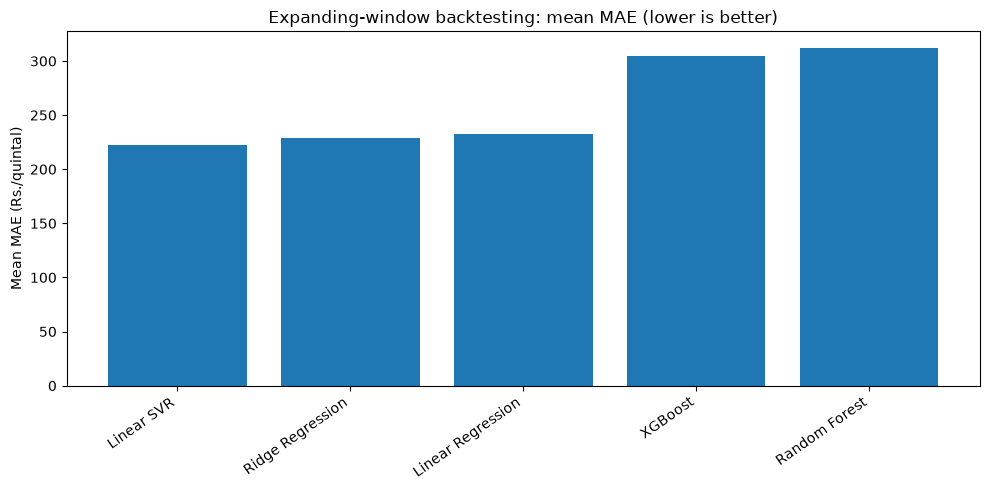

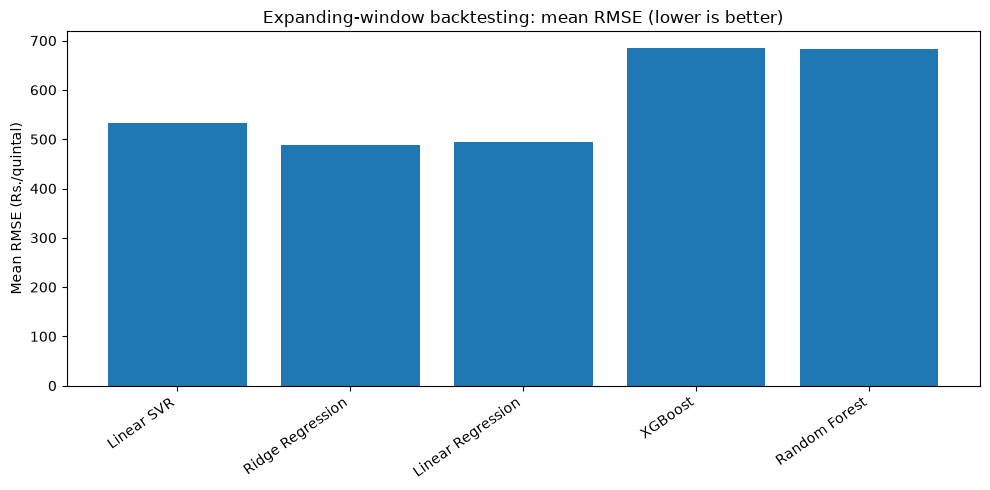

In [79]:
# Plot the primary evaluation metrics for the successful backtests.
import matplotlib.pyplot as plt

plot_df = backtest_summary.sort_values("Mean_MAE")

plt.figure(figsize=(10, 5))
plt.bar(plot_df["Model"], plot_df["Mean_MAE"])
plt.ylabel("Mean MAE (Rs./quintal)")
plt.title("Expanding-window backtesting: mean MAE (lower is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(plot_df["Model"], plot_df["Mean_RMSE"])
plt.ylabel("Mean RMSE (Rs./quintal)")
plt.title("Expanding-window backtesting: mean RMSE (lower is better)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [80]:
# Select the best candidate using mean backtesting MAE, with RMSE as tie-breaker.
import json
from pathlib import Path
from joblib import dump
from sklearn.pipeline import Pipeline
from sklearn.base import clone

complete_models = backtest_summary[backtest_summary["Folds_Completed"] == 3].copy()
if complete_models.empty:
    raise RuntimeError("No model completed all three folds. Fix failures before finalizing.")

best_row = complete_models.sort_values(["Mean_MAE", "Mean_RMSE"]).iloc[0]
best_model_name = best_row["Model"]
print("Selected candidate:", best_model_name)
print("Backtesting mean MAE:", round(float(best_row["Mean_MAE"]), 3))
print("Backtesting mean RMSE:", round(float(best_row["Mean_RMSE"]), 3))
print("Backtesting mean R²:", round(float(best_row["Mean_R2"]), 4))

final_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", clone(models[best_model_name]))
])
final_pipeline.fit(X, y)

model_path = Path("mandi_price_forecasting_pipeline.joblib")
metadata_path = Path("mandi_price_forecasting_metadata.json")
dump(final_pipeline, model_path)

metadata = {
    "selected_model": best_model_name,
    "target_column": target_col,
    "forecast_horizon_days": 7,
    "target_definition": "Modal price exactly 7 calendar days after Price Date; no substitution with next available observation",
    "feature_columns": feature_cols,
    "numeric_columns_scaled": scale_cols,
    "categorical_columns_encoded": categorical_cols,
    "training_rows": int(len(X)),
    "training_start_date": str(pd.to_datetime(dates).min().date()),
    "training_end_date": str(pd.to_datetime(dates).max().date()),
    "backtesting_mean_mae": float(best_row["Mean_MAE"]),
    "backtesting_mean_rmse": float(best_row["Mean_RMSE"]),
    "backtesting_mean_r2": float(best_row["Mean_R2"]),
    "note": "Weather features are historical same-day observations. A live forecast workflow must define how weather features will be available at prediction time."
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved pipeline:", model_path.resolve())
print("Saved metadata:", metadata_path.resolve())

Selected candidate: Linear SVR
Backtesting mean MAE: 222.69
Backtesting mean RMSE: 532.738
Backtesting mean R²: 0.9751
Saved pipeline: C:\New folder\Users\rajan\ML\karke dekhna\crop prediction\mandi_price_forecasting_pipeline.joblib
Saved metadata: C:\New folder\Users\rajan\ML\karke dekhna\crop prediction\mandi_price_forecasting_metadata.json
